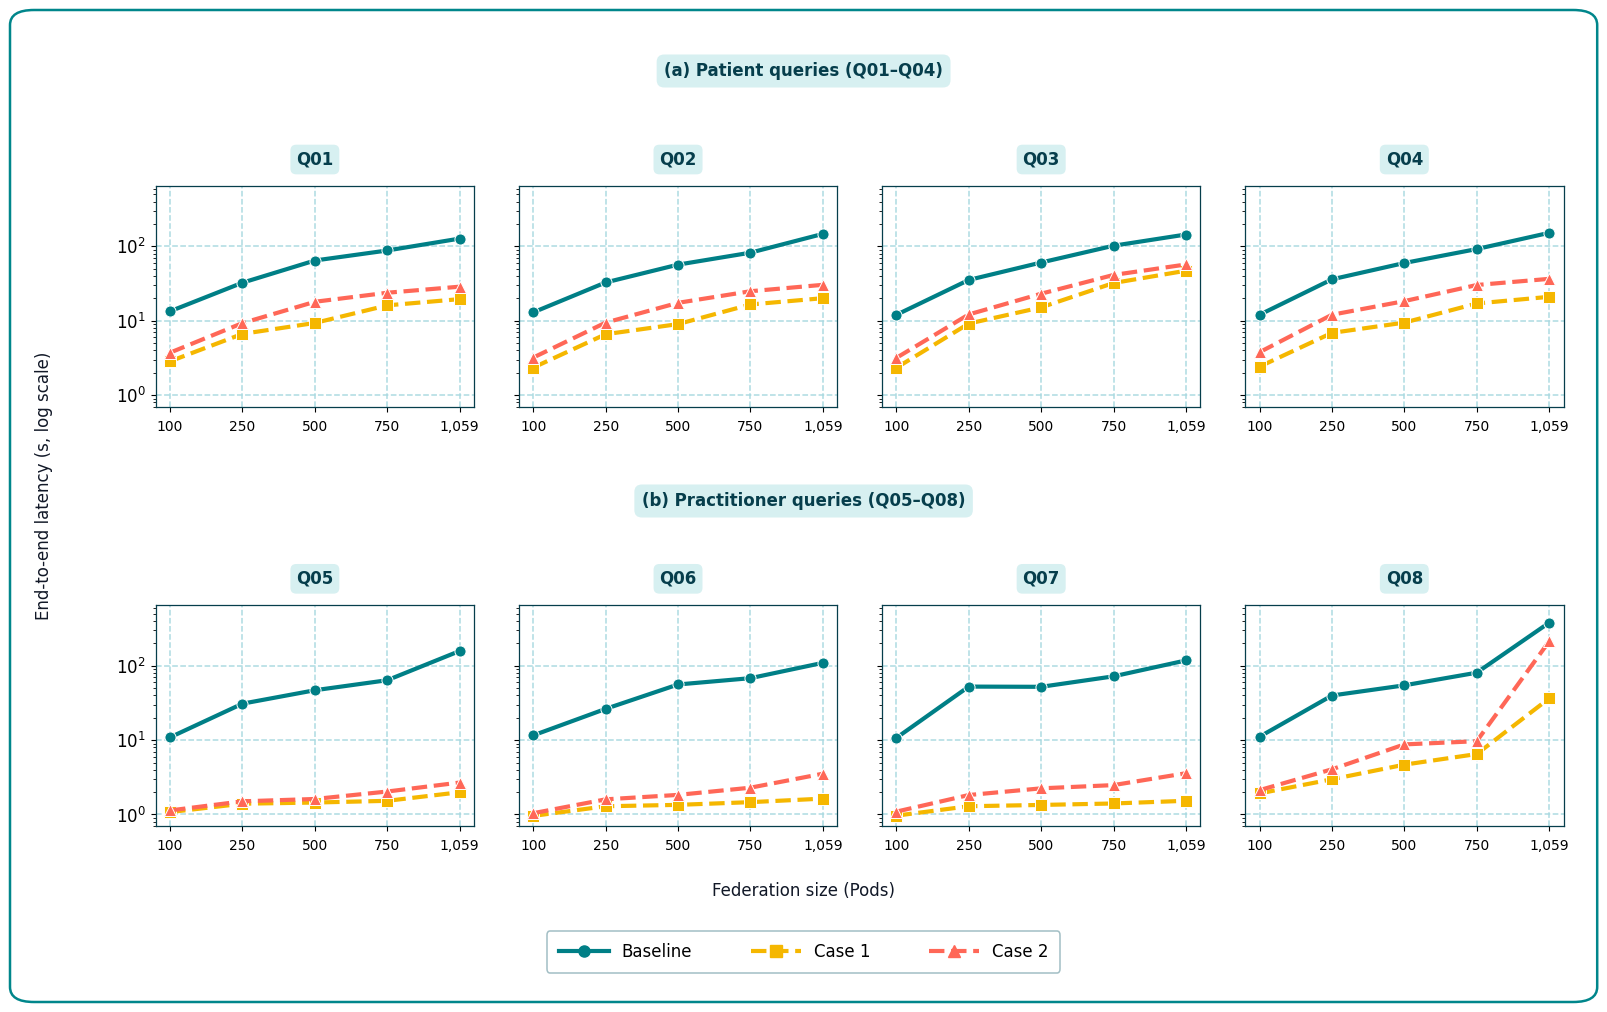

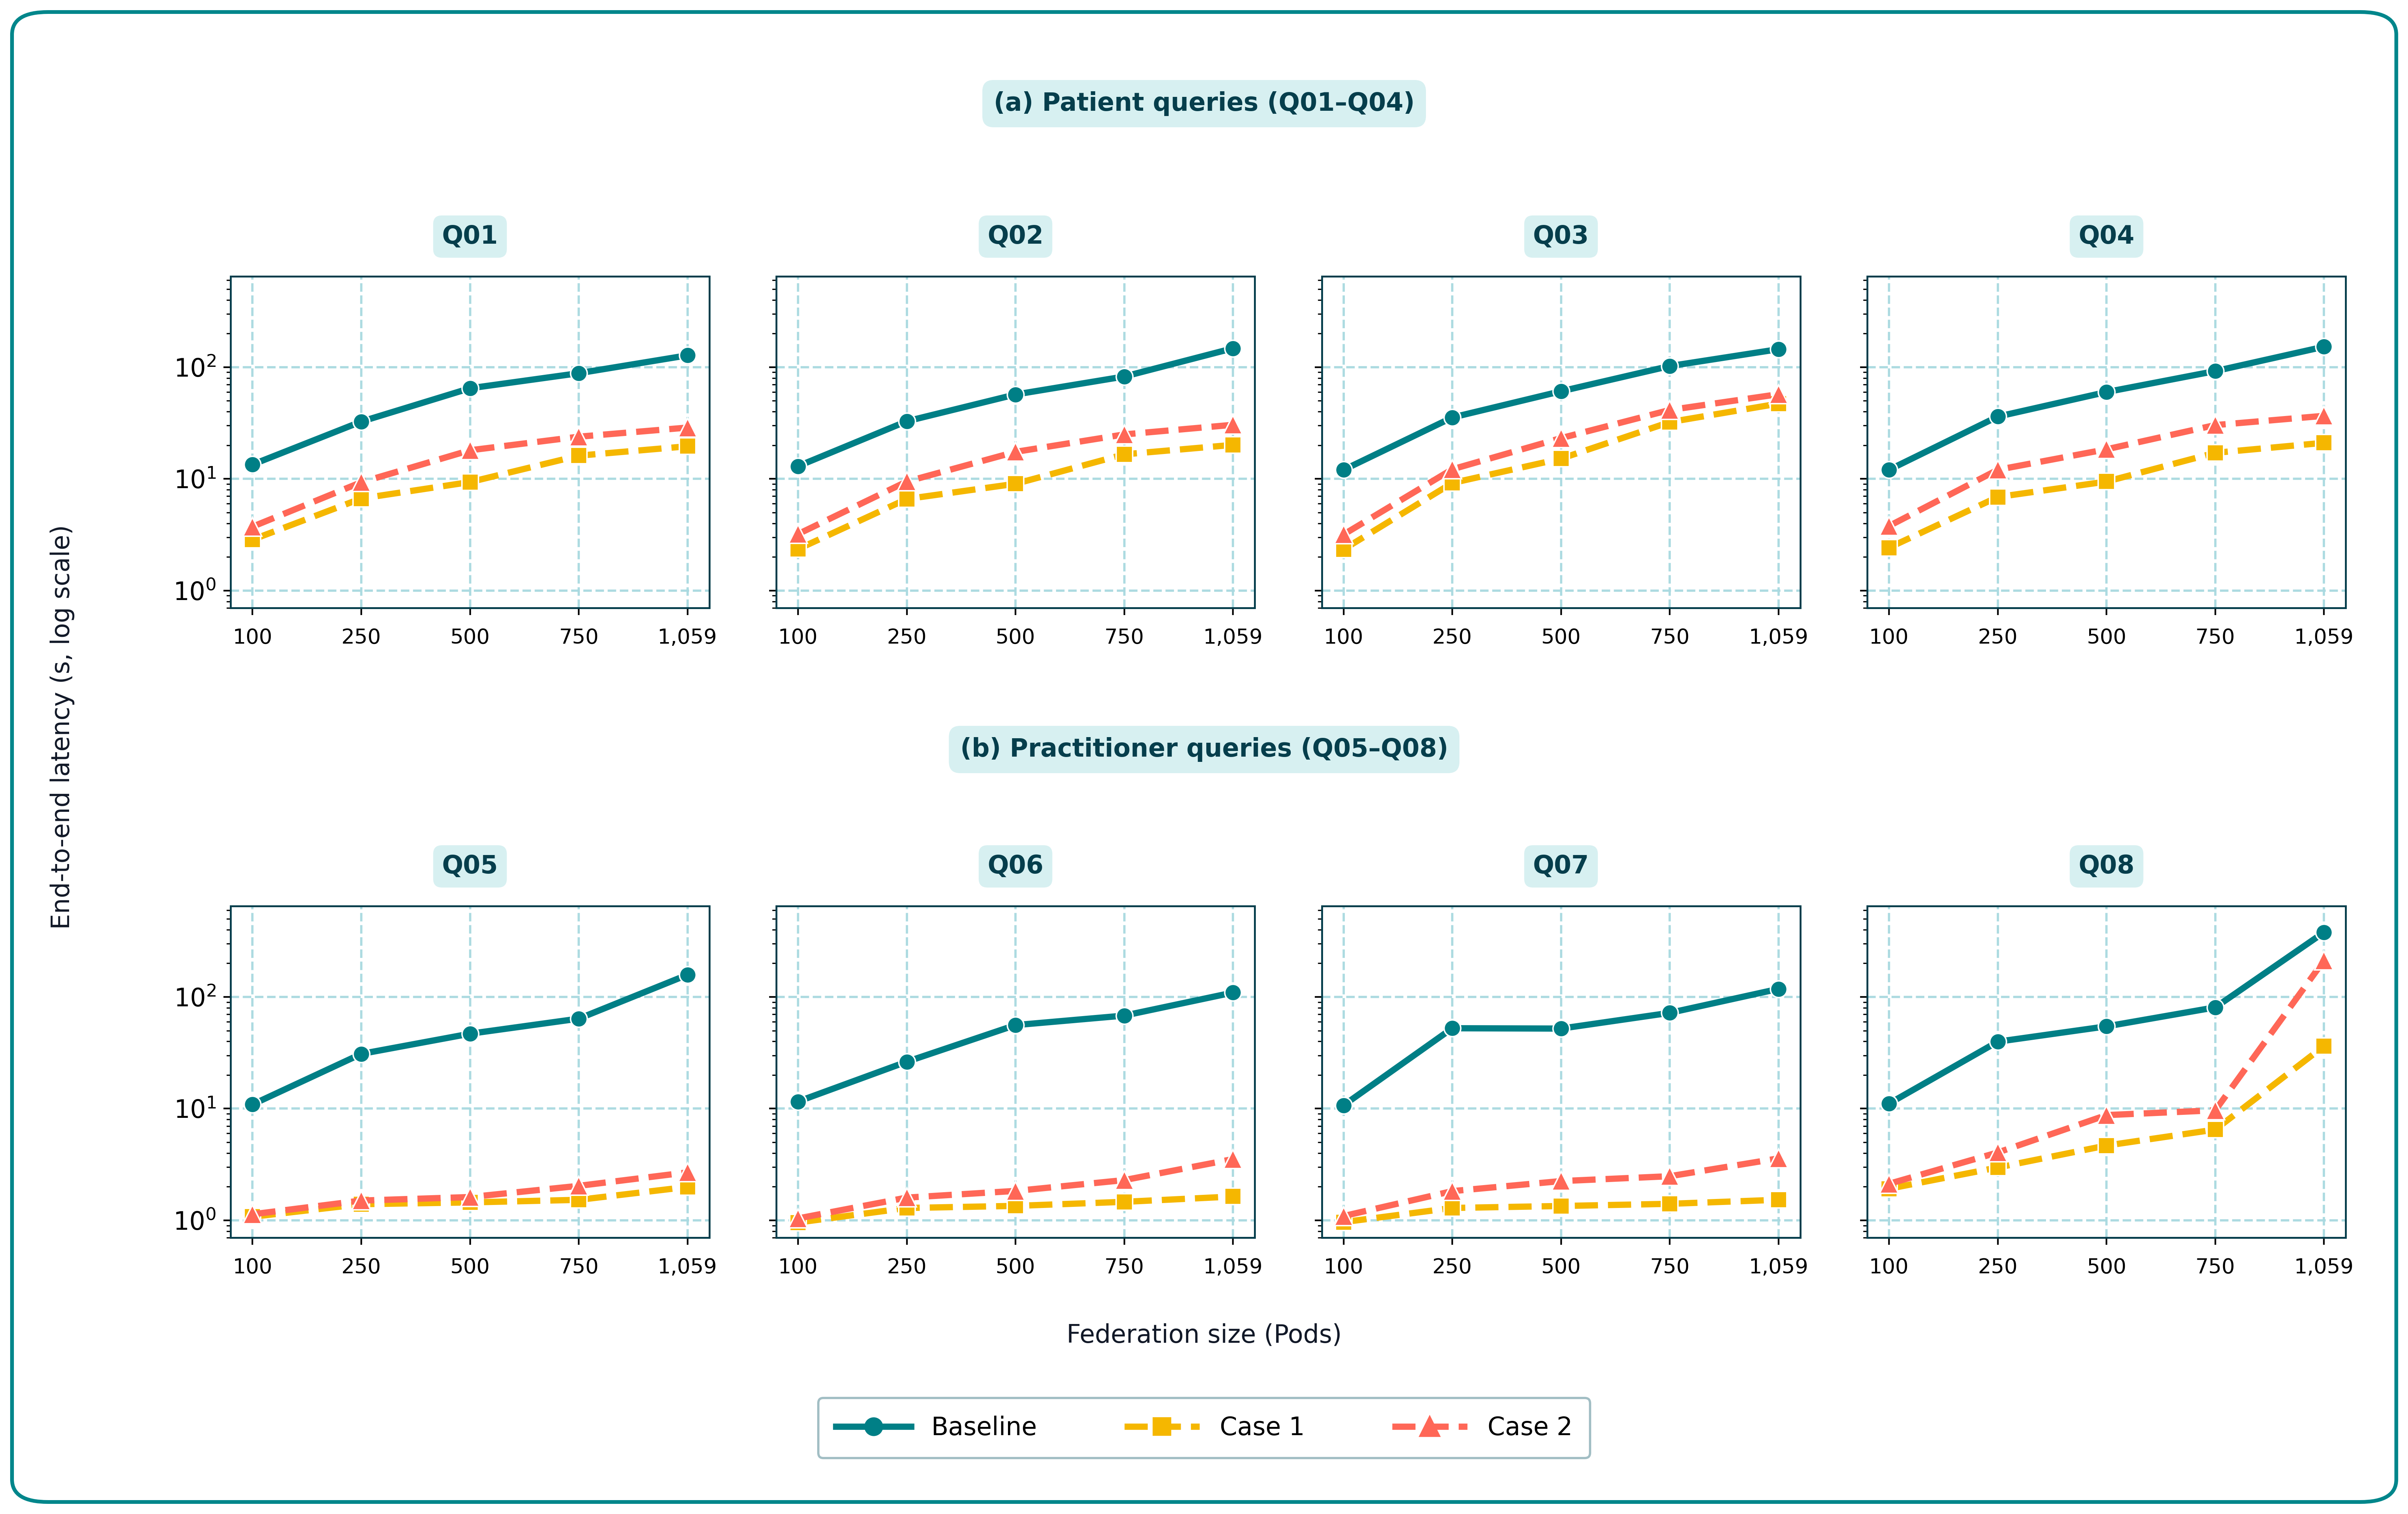

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

# ============================================================
# ESPRESSO FIGURE 3
# Colourful ICDE paper figure
#
# Baseline : Deep Teal
# Case 1   : Golden Yellow
# Case 2   : Coral
# ============================================================

pods = [100, 250, 500, 750, 1059]
x = np.arange(len(pods))

# ============================================================
# ACTUAL EXPERIMENTAL DATA
# End-to-end latency in milliseconds
# ============================================================

data = {
    "Q01": {
        "Baseline": [13433.65, 32561.17, 64711.61, 88271.41, 127569.57],
        "Case 1": [2853.78, 6670.77, 9357.52, 16133.45, 19571.33],
        "Case 2": [3730.98, 9320.86, 18024.81, 23847.57, 28775.50],
    },
    "Q02": {
        "Baseline": [12983.93, 32793.09, 56932.47, 82441.33, 147446.71],
        "Case 1": [2348.51, 6600.84, 9031.88, 16576.52, 20142.26],
        "Case 2": [3201.98, 9457.29, 17443.64, 24986.59, 30466.28],
    },
    "Q03": {
        "Baseline": [12030.56, 35440.91, 60830.25, 102285.69, 144771.18],
        "Case 1": [2334.94, 9181.30, 15164.85, 32235.08, 47163.75],
        "Case 2": [3173.81, 12185.04, 23156.68, 41376.75, 57231.69],
    },
    "Q04": {
        "Baseline": [12050.73, 36100.23, 59902.17, 92238.81, 152422.65],
        "Case 1": [2419.82, 6878.02, 9457.32, 17109.05, 21023.97],
        "Case 2": [3783.23, 12059.01, 18396.67, 30300.19, 36665.86],
    },
    "Q05": {
        "Baseline": [10902.08, 30921.91, 46873.66, 63923.76, 157919.79],
        "Case 1": [1077.34, 1395.49, 1447.46, 1525.99, 1990.85],
        "Case 2": [1133.36, 1503.17, 1615.80, 2035.93, 2687.42],
    },
    "Q06": {
        "Baseline": [11582.32, 26310.39, 56003.63, 68097.44, 109438.96],
        "Case 1": [956.88, 1289.99, 1346.82, 1464.76, 1634.17],
        "Case 2": [1040.29, 1597.40, 1834.00, 2292.07, 3533.82],
    },
    "Q07": {
        "Baseline": [10712.56, 52472.03, 52105.12, 72066.35, 118018.53],
        "Case 1": [964.23, 1290.89, 1343.81, 1405.77, 1527.95],
        "Case 2": [1092.35, 1826.12, 2246.32, 2483.71, 3587.34],
    },
    "Q08": {
        "Baseline": [11100.17, 39794.75, 54543.19, 80671.73, 379308.19],
        "Case 1": [1919.44, 2972.62, 4675.85, 6497.33, 36373.62],
        "Case 2": [2124.27, 4051.49, 8755.83, 9667.04, 212575.44],
    },
}

# ============================================================
# COLOUR PALETTE
# ============================================================

TEAL = "#007F86"
GOLD = "#F5B700"
CORAL = "#FF6757"

DARK_TEAL = "#063E4C"
GRID = "#A9D9E0"
HEADER_BG = "#D7F0F1"
BORDER = "#00868B"

styles = {
    "Baseline": {
        "color": TEAL,
        "marker": "o",
        "linestyle": "-",
        "linewidth": 3.0,
        "markersize": 8,
    },
    "Case 1": {
        "color": GOLD,
        "marker": "s",
        "linestyle": "--",
        "linewidth": 3.0,
        "markersize": 8,
    },
    "Case 2": {
        "color": CORAL,
        "marker": "^",
        "linestyle": "--",
        "linewidth": 3.0,
        "markersize": 9,
    },
}

# ============================================================
# GLOBAL FONT AND EXPORT SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 15,
    "xtick.labelsize": 11,
    "ytick.labelsize": 12,
    "axes.linewidth": 0.9,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})

# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

fig.patch.set_facecolor("white")

queries = [
    "Q01", "Q02", "Q03", "Q04",
    "Q05", "Q06", "Q07", "Q08"
]

# ============================================================
# DRAW ALL EIGHT QUERY PANELS
# ============================================================

for i, query in enumerate(queries):

    ax = axes.flat[i]

    ax.set_facecolor("white")

    for strategy in ["Baseline", "Case 1", "Case 2"]:

        latency_seconds = (
            np.array(data[query][strategy]) / 1000
        )

        ax.plot(
            x,
            latency_seconds,
            **styles[strategy],
            markeredgecolor="white",
            markeredgewidth=0.7,
            solid_capstyle="round",
            zorder=5
        )

    # Logarithmic latency axis
    ax.set_yscale("log")
    ax.set_ylim(0.7, 650)

    # X-axis
    ax.set_xticks(x)
    ax.set_xticklabels(
        ["100", "250", "500", "750", "1,059"],
        rotation=0
    )

    # Show x labels on both rows
    ax.tick_params(
        axis="x",
        labelbottom=True,
        labelsize=10,
        pad=6
    )

    # Colourful gridlines
    ax.grid(
        True,
        which="major",
        axis="both",
        color=GRID,
        linestyle="--",
        linewidth=1.1,
        alpha=0.95,
        zorder=0
    )

    ax.grid(
        False,
        which="minor"
    )

    ax.set_axisbelow(True)

    # Panel border
    for spine in ax.spines.values():
        spine.set_color(DARK_TEAL)
        spine.set_linewidth(0.9)

    # Query title with pale teal background
    ax.text(
        0.5,
        1.12,
        query,
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color=DARK_TEAL,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor=HEADER_BG,
            edgecolor="none"
        ),
        clip_on=False
    )

# ============================================================
# FIGURE SPACING
# ============================================================

fig.subplots_adjust(
    left=0.095,
    right=0.975,
    top=0.82,
    bottom=0.18,
    hspace=0.90,
    wspace=0.14
)

# ============================================================
# ROW HEADINGS
# ============================================================

fig.text(
    0.5,
    0.935,
    "(a) Patient queries (Q01–Q04)",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    color=DARK_TEAL,
    bbox=dict(
        boxstyle="round,pad=0.45",
        facecolor=HEADER_BG,
        edgecolor="none"
    )
)

fig.text(
    0.5,
    0.505,
    "(b) Practitioner queries (Q05–Q08)",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    color=DARK_TEAL,
    bbox=dict(
        boxstyle="round,pad=0.45",
        facecolor=HEADER_BG,
        edgecolor="none"
    )
)

# ============================================================
# SHARED AXIS LABELS
# ============================================================

fig.text(
    0.025,
    0.52,
    "End-to-end latency (s, log scale)",
    rotation=90,
    ha="center",
    va="center",
    fontsize=12,
    color="#111827"
)

fig.text(
    0.5,
    0.115,
    "Federation size (Pods)",
    ha="center",
    va="center",
    fontsize=12,
    color="#111827"
)

# ============================================================
# LEGEND
# ============================================================

handles = []

for strategy in ["Baseline", "Case 1", "Case 2"]:

    s = styles[strategy]

    handles.append(
        Line2D(
            [0], [0],
            color=s["color"],
            marker=s["marker"],
            linestyle=s["linestyle"],
            linewidth=s["linewidth"],
            markersize=s["markersize"],
            label=strategy
        )
    )

legend = fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=3,
    fontsize=12,
    frameon=True,
    fancybox=True,
    columnspacing=3.5,
    handlelength=3.0,
    borderpad=0.7
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("#8BAEB6")
legend.get_frame().set_linewidth(1.1)

# ============================================================
# DECORATIVE OUTER BORDER
# ============================================================

outer_border = FancyBboxPatch(
    (0.007, 0.007),
    0.986,
    0.986,
    transform=fig.transFigure,
    boxstyle="round,pad=0.003,rounding_size=0.015",
    linewidth=1.8,
    edgecolor=BORDER,
    facecolor="none",
    clip_on=False,
    zorder=20
)

fig.add_artist(outer_border)

# ============================================================
# SAVE HIGH-QUALITY FILES
# ============================================================

fig.savefig(
    "espresso_figure3_colorful.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.08
)

fig.savefig(
    "espresso_figure3_colorful.svg",
    format="svg",
    bbox_inches="tight",
    pad_inches=0.08
)

fig.savefig(
    "espresso_figure3_colorful.png",
    format="png",
    dpi=400,
    bbox_inches="tight",
    pad_inches=0.08
)

plt.show()

# ============================================================
# DISPLAY LARGE PNG IN GOOGLE COLAB
# ============================================================

from IPython.display import display, Image

display(
    Image(
        filename="espresso_figure3_colorful.png",
        width=1400
    )
)
